<a href="https://colab.research.google.com/github/deboraluz/deboraluz/blob/main/Profissao_Cientista_de_Dados_M20_Pratique.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MÓDULO 20 - Projeto de Credit Score - Naive Bayes**


No módulo 17 vocês realizaram a primeira etapa do projeto de crédito de vocês.
Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste.
Nessa aula aplicaremos o algoritmo de naive bayes a base de vocês afim de tentarmos trazer previsões do score de crédito.

**IMPORTANTE:** Não se esqueçam de ao enviar o código de vocês para os tutores, enviarem as bases, pois como cada um de vocês realizou as alterações de tratamento indidualmente o tutor precisa ter acesso aos seus dados individuais.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score

Durante a aula nossa variável a ser prevista (churn) continha apenas 2 categorias, a base de vocês contém mais. O Naive Bayes pode ser aplicado para problemas de classificação com múltiplas classes da mesma forma que para problemas de classificação binária. O Naive Bayes é um algoritmo de classificação probabilístico que calcula a probabilidade de uma amostra pertencer a cada classe e seleciona a classe com a maior probabilidade como a previsão final.
Em resumo, o Naive Bayes pode ser aplicado da mesma maneira para problemas de classificação com múltiplas classes, e os mesmos princípios se aplicam em termos de treinamento, avaliação e aplicação do modelo.

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [11]:
#bases
X_train = pd.read_csv('X_train_balanced.csv')
y_train = pd.read_csv('y_train_balanced.csv')
X_test = pd.read_csv('X_test.csv')
y_test = pd.read_csv('y_test.csv')

#numero de linhas e colunas
print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')

#verificando balanceamento
print('\nDistribuição de y_train:')
print(y_train['Churn'].value_counts())

print('\nDistribuição de y_test:')
print(y_test['Churn'].value_counts())

print('\nDistribuição das classes no Teste (y_test):')
print(y_test.value_counts(normalize=True))

X_train shape: (117950, 10)
y_train shape: (117950, 1)
X_test shape: (24927, 10)
y_test shape: (24927, 1)

Distribuição de y_train:
Churn
1.0    58975
0.0    58975
Name: count, dtype: int64

Distribuição de y_test:
Churn
0.0    19649
1.0     5278
Name: count, dtype: int64

Distribuição das classes no Teste (y_test):
Churn
0.0      0.788262
1.0      0.211738
Name: proportion, dtype: float64


# 2) Aplique o algoritmo de Naive Bayes aos dados de treinamento.

In [9]:
#modelo Naive Bayes
modelo_nb = GaussianNB()

#treinando o modelo
modelo_nb.fit(X_train, y_train['Churn'])

#previsões na base de treinamento
y_pred_train = modelo_nb.predict(X_train)

# 3) Faça a avaliação do modelo com os dados de treinamento.
Traga a acurácia, recall e plote a matriz de confusão. Não se esqueça de avaliar com suas palavras o desempenho do modelo, interpretando as métricas.

Dica: Para calcularmos o recall em classificação multi classe precisamos usar o atributo macro:
recall = recall_score(y_train, y_pred_train, average='macro')

Acurácia (Treino): 0.5855
Recall Macro (Treino): 0.5855


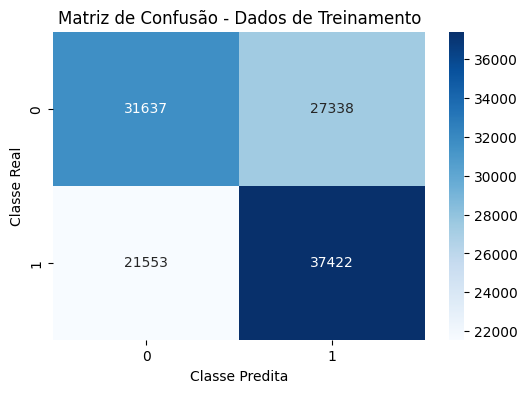

In [12]:
#predições nos dados de treino
y_pred_train = gnb.predict(X_train)

#métricas de treino
acc_train = accuracy_score(y_train, y_pred_train)
rec_train = recall_score(y_train, y_pred_train, average='macro')
cm_train = confusion_matrix(y_train, y_pred_train)

print(f'Acurácia (Treino): {acc_train:.4f}')
print(f'Recall Macro (Treino): {rec_train:.4f}')

#matriz de Confusão do Treino
plt.figure(figsize=(6, 4))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão - Dados de Treinamento')
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.show()

# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados, da mesma forma que fez acima. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

Acurácia (Teste): 0.5553
Recall Macro (Teste): 0.5892


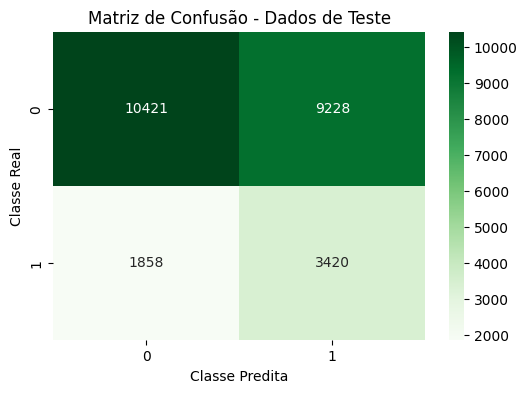

In [14]:
#predições nos dados de teste
y_pred_test = gnb.predict(X_test)

#métricas de teste
acc_test = accuracy_score(y_test, y_pred_test)
rec_test = recall_score(y_test, y_pred_test, average='macro')
cm_test = confusion_matrix(y_test, y_pred_test)

print(f'Acurácia (Teste): {acc_test:.4f}')
print(f'Recall Macro (Teste): {rec_test:.4f}')

#matriz de Confusão do Teste
plt.figure(figsize=(6, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens')
plt.title('Matriz de Confusão - Dados de Teste')
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.show()

# 5) Descreva com suas palavras o projeto desenvolvido nessa atividade e qual o nosso objetivo principal ao aplicarmos o algoritmo de naive bayes a base de crédito.
Utilize pelo menos 4 linhas.

Dica: Caso você ainda esteja tendo dificuldade em visualizar a aplicação dos projetos e objetivo, consulte seus tutores!

Neste projeto foi aplicado o algoritmo de Naive Bayes a uma base de dados de crédito previamente preparada e dividida em dados de treinamento e teste. O objetivo principal foi utilizar as características dos clientes para realizar a classificação da variável Churn. O modelo foi treinado com a base de treinamento e posteriormente avaliado utilizando acurácia, recall e matriz de confusão. Por fim, os resultados obtidos nas bases de treinamento e teste foram comparados para verificar o desempenho do modelo em dados que não participaram do treinamento.